In [1]:
import pandas as pd
import numpy as np
import re
import html
import time
import joblib
import warnings
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
print("All libraries imported successfully!")
RANDOM_STATE = 42
BEST_PREPROCESSING = "E2" 
print("Random state:", RANDOM_STATE)
print("Selected preprocessing:", BEST_PREPROCESSING)

All libraries imported successfully!
Random state: 42
Selected preprocessing: E2


In [2]:
PROJECT_ROOT = None
for folder in [Path.cwd(), *Path.cwd().parents]:
    candidate = folder / "data" / "processed" / "train.csv"
    if candidate.exists():
        PROJECT_ROOT = folder
        DATA_PATH = candidate
        break
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate data/processed/train.csv.")
train_df = pd.read_csv(DATA_PATH)
print("Project root:", PROJECT_ROOT)
print("Dataset loaded successfully!")
print("Dataset shape:", train_df.shape)
print("\nSentiment distribution:")
print(train_df["sentiment"].value_counts())
X = train_df["review"]
y = train_df["sentiment"]

Project root: c:\Users\VRINDA ARORA\OneDrive\Desktop\Sentient-Beings-Review-Sentiment
Dataset loaded successfully!
Dataset shape: (40000, 3)

Sentiment distribution:
sentiment
positive    20000
negative    20000
Name: count, dtype: int64


In [3]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("\nTraining distribution:")
print(y_train.value_counts())
print("\nValidation distribution:")
print(y_val.value_counts())

Training samples: 32000
Validation samples: 8000

Training distribution:
sentiment
negative    16000
positive    16000
Name: count, dtype: int64

Validation distribution:
sentiment
positive    4000
negative    4000
Name: count, dtype: int64


In [4]:
def remove_html(text):
    text = re.sub(r"<[^>]+>", " ", text)
    text = html.unescape(text)
    text = re.sub(r"\s+", " ", text).strip()
    return text
def lowercase(text):
    return text.lower()
def remove_punctuation(text):
    return re.sub(r"[^\w\s]", " ", text)
def remove_stopwords(text):
    words = text.split()
    filtered_words = [word for word in words if word not in ENGLISH_STOP_WORDS]
    return " ".join(filtered_words)
import nltk
from nltk.stem import PorterStemmer
from nltk.stem import WordNetLemmatizer
try:
    nltk.data.find("corpora/wordnet")
except LookupError:
    nltk.download("wordnet")
try:
    nltk.data.find("corpora/omw-1.4")
except LookupError:
    nltk.download("omw-1.4")
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()
def stem_text(text):
    return " ".join(stemmer.stem(word) for word in text.split())
def lemmatize_text(text):
    return " ".join(lemmatizer.lemmatize(word) for word in text.split())
def preprocess_E1(text):
    return remove_html(text)
def preprocess_E2(text):
    return lowercase(remove_html(text))
def preprocess_E3(text):
    return remove_punctuation(lowercase(remove_html(text)))
def preprocess_E4(text):
    return remove_stopwords(
        remove_punctuation(lowercase(remove_html(text))))
def preprocess_E5(text):
    return stem_text(preprocess_E4(text))
def preprocess_E6(text):
    return lemmatize_text(preprocess_E4(text))
PREPROCESSING_OPTIONS = {
    "E1": preprocess_E1,
    "E2": preprocess_E2,
    "E3": preprocess_E3,
    "E4": preprocess_E4,
    "E5": preprocess_E5,
    "E6": preprocess_E6}
if BEST_PREPROCESSING not in PREPROCESSING_OPTIONS:
    raise ValueError("Invalid preprocessing selection!")
selected_preprocessor = PREPROCESSING_OPTIONS[BEST_PREPROCESSING]
print("Preprocessing function selected:", BEST_PREPROCESSING)

Preprocessing function selected: E2


[nltk_data] Downloading package wordnet to C:\Users\VRINDA
[nltk_data]     ARORA\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to C:\Users\VRINDA
[nltk_data]     ARORA\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [5]:
sample_review = X_train.iloc[0]
print("ORIGINAL REVIEW:\n")
print(sample_review[:500])
print("\nPROCESSED REVIEW:\n")
print(selected_preprocessor(sample_review)[:500])
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Multinomial Naive Bayes": MultinomialNB(),
    "Linear SVM": LinearSVC(random_state=RANDOM_STATE)}
vectorizers = {
    "Bag-of-Words": CountVectorizer(preprocessor=selected_preprocessor, lowercase=False, token_pattern=r"(?u)\b\w\w+\b"),
    "TF-IDF": TfidfVectorizer(preprocessor=selected_preprocessor, lowercase=False, token_pattern=r"(?u)\b\w\w+\b")}
print("Models and vectorizers configured successfully!")

ORIGINAL REVIEW:

Scooby Doo is undoubtedly one of the most simple, successful and beloved cartoon characters in the world. So, what happens when you've been everywhere and done everything with the formula? You switch it up right? Wrong. You stop production and let it rest for a decade or so and then run it again, keeping the core of its success intact. That is to say, stick with the formula for the most part but add your particular flavour to it. This to me is why "What's New Scooby Doo" worked, they want back t

PROCESSED REVIEW:

scooby doo is undoubtedly one of the most simple, successful and beloved cartoon characters in the world. so, what happens when you've been everywhere and done everything with the formula? you switch it up right? wrong. you stop production and let it rest for a decade or so and then run it again, keeping the core of its success intact. that is to say, stick with the formula for the most part but add your particular flavour to it. this to me is why "what's n

In [ ]:
results = []
trained_models = {}
for vectorizer_name, vectorizer in vectorizers.items():
    for model_name, classifier in models.items():
        print("\n" + "=" * 60)
        print("Vectorizer:", vectorizer_name)
        print("Model:", model_name)
        print("=" * 60)
        pipeline = Pipeline([("vectorizer", vectorizer), ("classifier", classifier)])
        start_time = time.time()
        pipeline.fit(X_train, y_train)
        y_pred = pipeline.predict(X_val)
        if hasattr(pipeline.named_steps["classifier"], "predict_proba"):
            positive_index = list(pipeline.classes_).index("positive")
            y_scores = pipeline.predict_proba(X_val)[:, positive_index]
        else:
            y_scores = pipeline.decision_function(X_val)
        runtime = time.time() - start_time
        accuracy = accuracy_score(y_val, y_pred)
        precision = precision_score(y_val, y_pred, pos_label="positive")
        recall = recall_score(y_val, y_pred, pos_label="positive")
        f1 = f1_score(y_val, y_pred, pos_label="positive")
        roc_auc = roc_auc_score((y_val == "positive").astype(int),y_scores)
        feature_count = len(pipeline.named_steps["vectorizer"].vocabulary_)
        results.append({"Vectorizer": vectorizer_name,
            "Model": model_name,
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1-Score": f1,
            "ROC-AUC": roc_auc,
            "Training Time (seconds)": runtime,
            "Features": feature_count})
        trained_models[f"{vectorizer_name} + {model_name}"] = pipeline
        print("Accuracy:", round(accuracy, 4))
        print("Precision:", round(precision, 4))
        print("Recall:", round(recall, 4))
        print("F1-score:", round(f1, 4))
        print("ROC-AUC:", round(roc_auc, 4))
        print("Training time:", round(runtime, 2), "seconds")
        print("Number of features:", feature_count)
print("\nAll six experiments completed!")


Vectorizer: Bag-of-Words
Model: Logistic Regression
Accuracy: 0.8855
Precision: 0.8792
Recall: 0.8938
F1-score: 0.8864
ROC-AUC: 0.9515
Training time: 32.65 seconds
Number of features: 84297

Vectorizer: Bag-of-Words
Model: Multinomial Naive Bayes
Accuracy: 0.8489
Precision: 0.8722
Recall: 0.8175
F1-score: 0.844
ROC-AUC: 0.919
Training time: 13.65 seconds
Number of features: 84297

Vectorizer: Bag-of-Words
Model: Linear SVM
Accuracy: 0.8688
Precision: 0.8642
Recall: 0.875
F1-score: 0.8696
ROC-AUC: 0.938
Training time: 24.14 seconds
Number of features: 84297

Vectorizer: TF-IDF
Model: Logistic Regression
Accuracy: 0.8921
Precision: 0.8832
Recall: 0.9038
F1-score: 0.8934
ROC-AUC: 0.9602
Training time: 14.44 seconds
Number of features: 84297

Vectorizer: TF-IDF
Model: Multinomial Naive Bayes
Accuracy: 0.8641
Precision: 0.8818
Recall: 0.841
F1-score: 0.8609
ROC-AUC: 0.9382
Training time: 13.09 seconds
Number of features: 84297

Vectorizer: TF-IDF
Model: Linear SVM
Accuracy: 0.8994
Precisio

In [ ]:
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by=["F1-Score", "ROC-AUC"], ascending=False).reset_index(drop=True)
print("MODEL COMPARISON RESULTS\n")
display(results_df.round(4))
best_result = results_df.iloc[0]
best_model_name = (f"{best_result['Vectorizer']} + {best_result['Model']}")
best_model = trained_models[best_model_name]
print("BEST MODEL CONFIGURATION")
print("-" * 40)
print("Vectorizer:", best_result["Vectorizer"])
print("Model:", best_result["Model"])
print("Preprocessing:", BEST_PREPROCESSING)
print("\nPerformance:")
print("Accuracy:", round(best_result["Accuracy"], 4))
print("Precision:", round(best_result["Precision"], 4))
print("Recall:", round(best_result["Recall"], 4))
print("F1-score:", round(best_result["F1-Score"], 4))
print("ROC-AUC:", round(best_result["ROC-AUC"], 4))

MODEL COMPARISON RESULTS



,Vectorizer,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Training Time (seconds),Features
0,TF-IDF,Linear SVM,0.8994,0.8907,0.9105,0.9005,0.9640,13.5241,84297
1,TF-IDF,Logistic Regression,0.8921,0.8832,0.9038,0.8934,0.9602,14.4404,84297
2,Bag-of-Words,Logistic Regression,0.8855,0.8792,0.8938,0.8864,0.9515,32.6533,84297
3,Bag-of-Words,Linear SVM,0.8688,0.8642,0.8750,0.8696,0.9380,24.1389,84297
4,TF-IDF,Multinomial Naive Bayes,0.8641,0.8818,0.8410,0.8609,0.9382,13.0922,84297
5,Bag-of-Words,Multinomial Naive Bayes,0.8489,0.8722,0.8175,0.8440,0.9190,13.6476,84297


BEST MODEL CONFIGURATION
----------------------------------------
Vectorizer: TF-IDF
Model: Linear SVM
Preprocessing: E2

Performance:
Accuracy: 0.8994
Precision: 0.8907
Recall: 0.9105
F1-score: 0.9005
ROC-AUC: 0.964


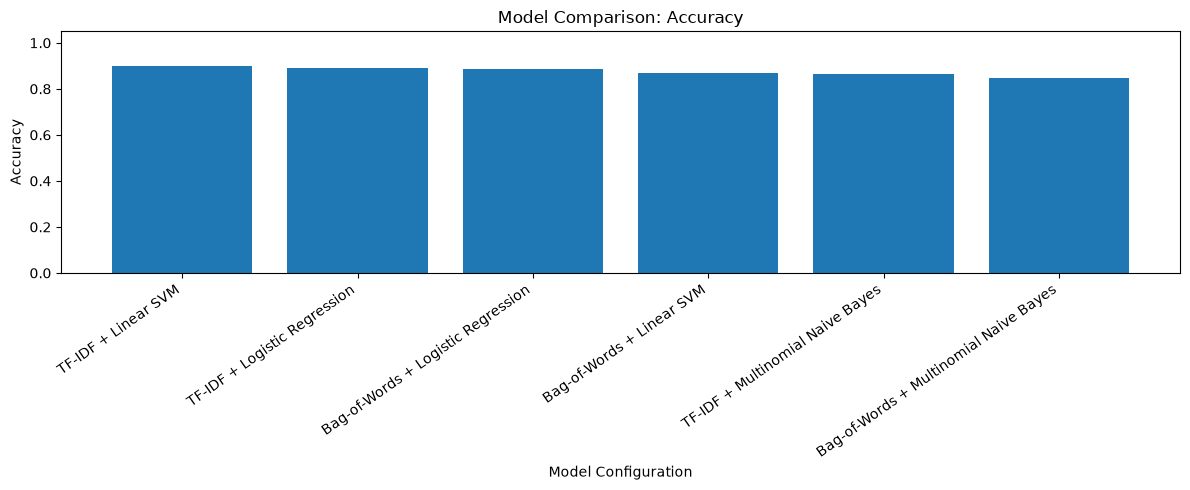

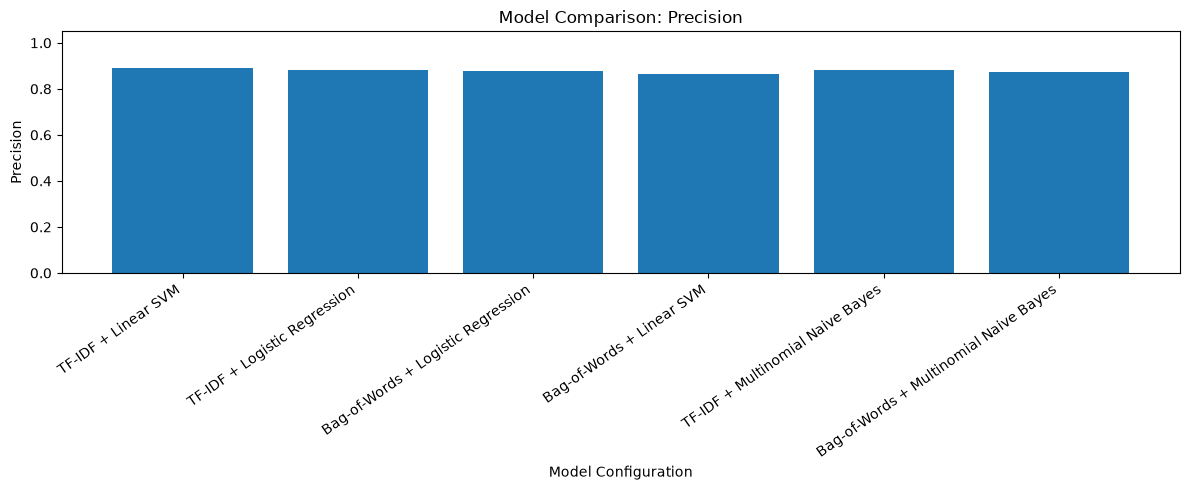

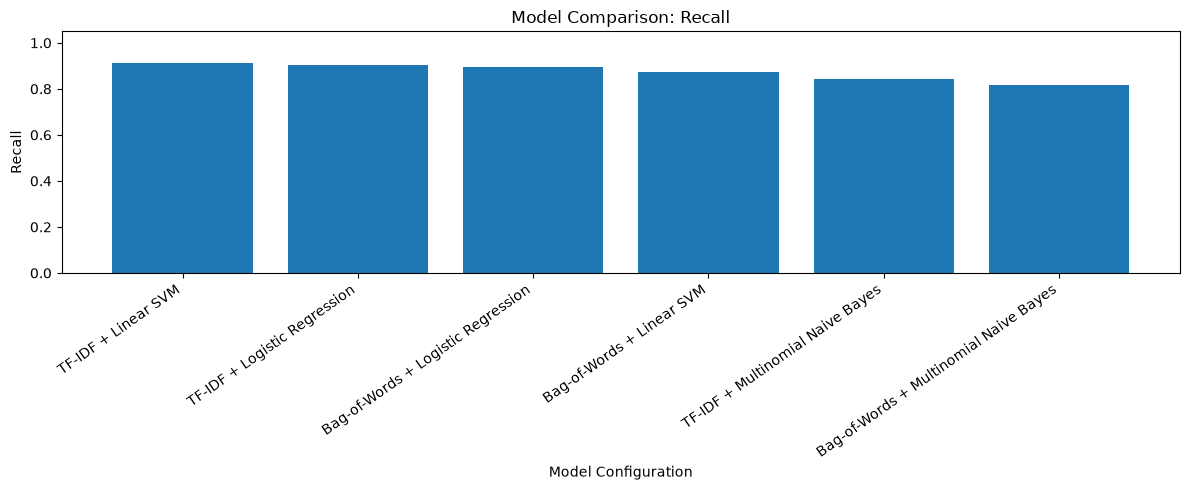

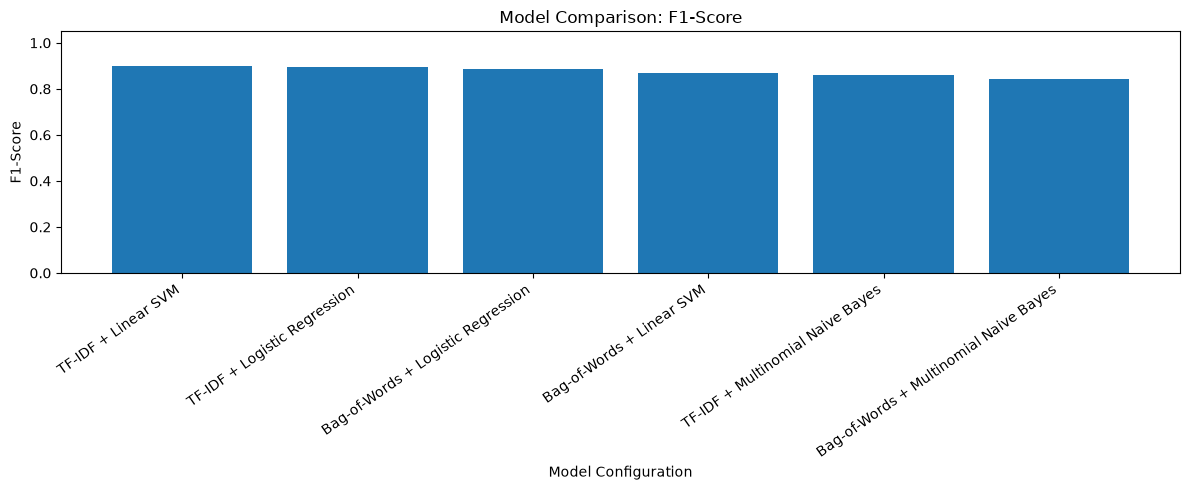

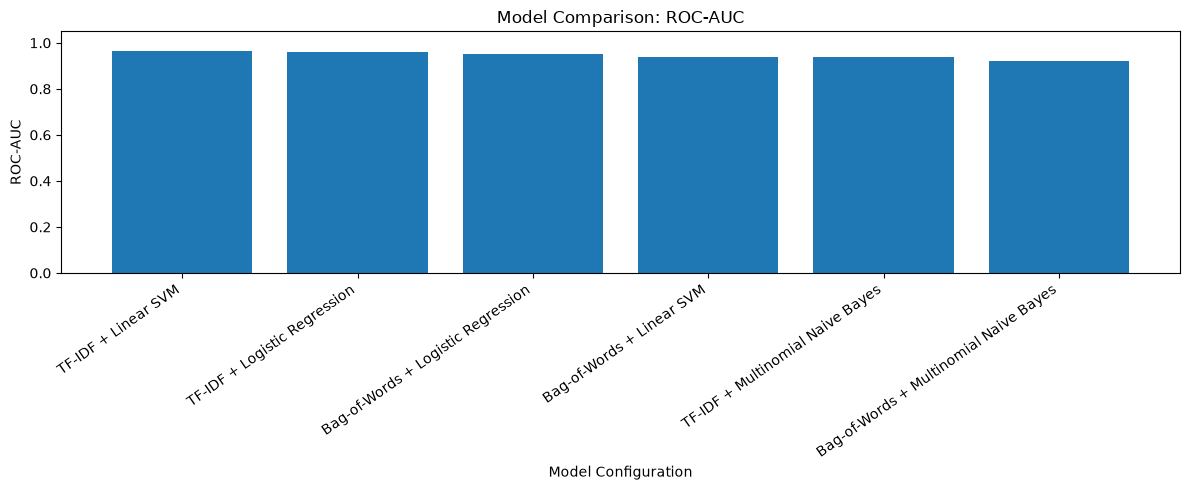

In [ ]:
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
for metric in metrics_to_plot:
    plt.figure(figsize=(12, 5))
    labels = (results_df["Vectorizer"]+ " + "+ results_df["Model"])
    plt.bar(labels, results_df[metric])
    plt.title(f"Model Comparison: {metric}")
    plt.xlabel("Model Configuration")
    plt.ylabel(metric)
    plt.xticks(rotation=35, ha="right")
    plt.ylim(0, 1.05)
    plt.tight_layout()
    plt.show()


Best configuration: TF-IDF + Linear SVM
CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative       0.91      0.89      0.90      4000
    Positive       0.89      0.91      0.90      4000

    accuracy                           0.90      8000
   macro avg       0.90      0.90      0.90      8000
weighted avg       0.90      0.90      0.90      8000



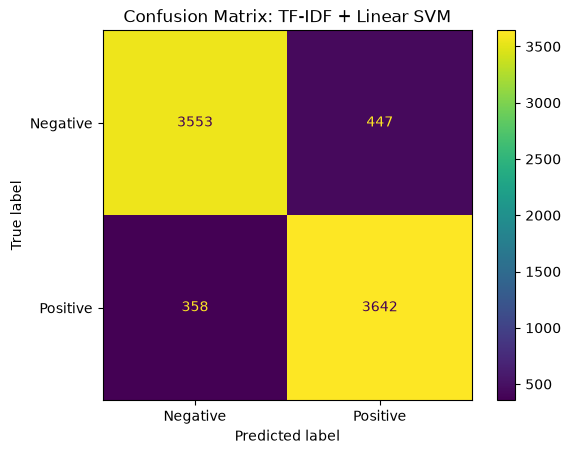

In [ ]:
print("\nBest configuration:", best_model_name)
best_predictions = best_model.predict(X_val)
print("CLASSIFICATION REPORT")
print("=" * 60)
print(classification_report(y_val, best_predictions, target_names=["Negative", "Positive"]))
cm = confusion_matrix(y_val, best_predictions, labels=["negative", "positive"])
display_labels = ["Negative", "Positive"]
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=display_labels)
disp.plot()
plt.title(f"Confusion Matrix: {best_model_name}")
plt.show()

In [ ]:
results_dir = PROJECT_ROOT / "results"
models_dir = results_dir / "models"
figures_dir = results_dir / "figures"
models_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)
results_df.to_csv(results_dir / "model_comparison_results.csv", index=False)
joblib.dump(best_model, models_dir / "best_model_comparison.pkl")
predictions_df = pd.DataFrame({
    "review": X_val.reset_index(drop=True),
    "actual_sentiment": y_val.reset_index(drop=True),
    "predicted_sentiment": best_predictions})
predictions_df.to_csv(results_dir / "best_model_validation_predictions.csv", index=False)
print("Results and best model saved successfully!")
print("Saved in:", results_dir)

Results and best model saved successfully!
Saved in: c:\Users\VRINDA ARORA\OneDrive\Desktop\Sentient-Beings-Review-Sentiment\results


In [ ]:
print("=" * 60)
print("PHASE D: MODEL COMPARISON SUMMARY")
print("=" * 60)
print("\nPreprocessing used:", BEST_PREPROCESSING)
print("Best model:", best_model_name)
print("\nBest validation performance:")
print(f"Accuracy:  {best_result['Accuracy']:.4f}")
print(f"Precision: {best_result['Precision']:.4f}")
print(f"Recall:    {best_result['Recall']:.4f}")
print(f"F1-score:  {best_result['F1-Score']:.4f}")
print(f"ROC-AUC:   {best_result['ROC-AUC']:.4f}")
print("\nTotal configurations tested:", len(results_df))
print("\nNotebook 04 completed successfully!")

PHASE D: MODEL COMPARISON SUMMARY

Preprocessing used: E2
Best model: TF-IDF + Linear SVM

Best validation performance:
Accuracy:  0.8994
Precision: 0.8907
Recall:    0.9105
F1-score:  0.9005
ROC-AUC:   0.9640

Total configurations tested: 6

Notebook 04 completed successfully!
